# Question 1 (18 pts) 
We will look into the NYC flights dataset using Pandas!

## Question 1.1 (2 pts)
Load the dataset from flights.csv file given with this file into a dataframe variable named `df`

In [130]:
import pandas as pd
df = pd.read_csv('flights.csv')

In [127]:
assert df is not None
assert isinstance(df, pd.core.frame.DataFrame)

## Question 1.2 (2 pts)
Get the total count of flights for each month and display the top three months with the highest count.

In [131]:
df.head(3)

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400.0,5.0,15.0,1.357034e+09
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416.0,5.0,29.0,1.357034e+09
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089.0,5.0,40.0,1.357034e+09


In [35]:
df[['month', 'flight']].groupby('month').count().sort_values('flight', ascending = False)


,flight
month,
7,29425
8,29327
10,28889
3,28834
5,28796
4,28330
6,28243
12,28135
9,27574


In [33]:
monthly_count = df['month'].value_counts().sort_values(ascending = False).head(3)

In [34]:
assert all(monthly_count == pd.Series([29425, 29327, 28889], index = [7, 8, 10]))

## Question 1.3 (2 pts)
First get a new dataframe with the three columns of interest 'carrier', 'month' and 'dep_delay'. Then compute the average dep_delay for each carrier and for each month. Rank the departure delays/month and filter the 1st rank carrier for each month (carrier with the lowest dep_delay for the month will get the 1st rank). Show the results in ascending order of the month

Hint: Some of the functions that can help are rank(), unstack(), stack(). 

In [36]:
df.head(3)

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400.0,5.0,15.0,1.357034e+09
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416.0,5.0,29.0,1.357034e+09
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089.0,5.0,40.0,1.357034e+09


In [80]:
delay_avg = df[['carrier', 'month', 'dep_delay']].groupby(['month', 'carrier']).mean() #average delay
delay_avg['rank'] = delay_avg.groupby('month').rank() #rank delay within each month
delay_avg[delay_avg['rank'] == 1].sort_values('month')
# delay_avg[0:45]

,,dep_delay,rank
month,carrier,,
1,VX,1.063492,1.0
2,AS,0.722222,1.0
3,HA,1.161290,1.0
4,HA,-2.100000,1.0
5,HA,-1.451613,1.0
6,HA,1.466667,1.0
7,HA,-1.709677,1.0
8,HA,1.677419,1.0
9,HA,-5.440000,1.0


In [81]:

df_new = df[['carrier', 'month', 'dep_delay']]
delay_avg = df_new.groupby(['month', 'carrier']).mean() #average delay
delay_avg['rank'] = delay_avg.groupby('month').rank() #rank delay within each month

avg_delay = delay_avg[delay_avg['rank'] == 1].sort_values('month')

In [ ]:
# Hidden test here

## Question 1.4 (2 pts)
Find the 5 top destinations in this dataset (most number of flights to). Filter only those flights to these top 5 destinations and then show the distribution of carriers on this filtered data.

In [82]:
df.head(3)

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400.0,5.0,15.0,1.357034e+09
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416.0,5.0,29.0,1.357034e+09
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089.0,5.0,40.0,1.357034e+09


In [104]:
top_dest = df['dest'].value_counts().sort_values(ascending = False).head(5).index.tolist()
top_carrier_count = df[df['dest'].isin(top_dest)]['carrier'].value_counts().sort_values(ascending = False)

In [105]:
import numpy as np
assert np.all(top_dest == np.array(['ORD', 'ATL', 'LAX', 'BOS', 'MCO']))

## Question 1.5 (2 pts)
Get the total count of cancelled flights in this dataset. We'll say that a cancelled flight has dep_time missing.

In [112]:
cancelled_flight_count = len(df[df['dep_time'].isna()])

In [113]:
assert cancelled_flight_count == 8255

## Question 1.6 (2 pts)
Count all the destinations that have a letter 'K' anywhere in the name code.

In [117]:
dest_with_k = len(df[df['dest'].str.contains('K', na = False)])

In [118]:
assert dest_with_k == 4589

## Question 1.7 (2 pts)
Create a new column called speed that computes the speed as distance/air_time

In [122]:
df['speed'] = df['distance']/df['air_time']

In [123]:
assert type(df['speed']) == pd.Series 
assert abs(df['speed'][0] - 6.1674) < 1

## Question 1.8 (4 pts)
Segment the dep_time 24 hours into 
* night from 12 midnight to 5 am
* morning from 5:01 am to 12 noon
* afternoon from 12.01 noon to 5 pm
* evening from 5.01 pm to 12 am

And then run a query to find the total flights in each segment and save that value in the given variable.


In [125]:
df.head(3)

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,speed
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400.0,5.0,15.0,1.357034e+09,6.167401
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416.0,5.0,29.0,1.357034e+09,6.237885
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089.0,5.0,40.0,1.357034e+09,6.806250


<Axes: >

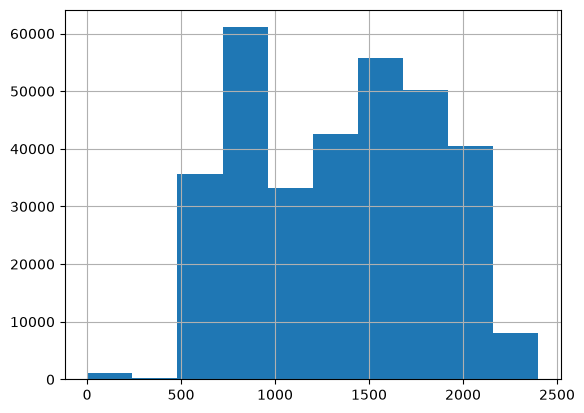

In [146]:
df['dep_time'].hist()

In [ ]:
df['part_of_day'] = None
df.loc[df['dep_time'] <= 500, 'part_of_day'] = "night"
df.loc[(df['dep_time'] > 500) & (df['dep_time'] <= 1200), 'part_of_day'] = "morning"
df.loc[(df['dep_time'] > 1200) & (df['dep_time'] <= 1700), 'part_of_day'] = "afternoon"
df.loc[(df['dep_time'] > 1700) & (df['dep_time'] <= 2400), 'part_of_day'] = "evening"
df['part_of_day'].value_counts()

part_of_day
morning      129939
afternoon     98733
evening       98362
night          1487
Name: count, dtype: int64

In [149]:
parts_of_day_count = df['part_of_day'].value_counts(ascending = False)

In [150]:
assert parts_of_day_count['morning'] == 129939
assert parts_of_day_count['evening'] == 98362

# Question 2 (9 pts) 
In this problem, we will do some exploratory data analytics (EDA) by using some of the visualization libraries in Python.

In [152]:
import numpy as np
import pandas as pd
import seaborn as sns
flights = pd.read_csv("flights.csv.gz")
airports = pd.read_csv("airports.csv")
flights.describe()

ModuleNotFoundError: No module named 'seaborn'

## Question 2.1 (3 pts)

Line charts are ideal to show a trend line. Draw a line chart to show monthly frequency count of flights as a trend line for the year 2013. Be sure to choose the correct data to display on the x-axis and y-axis.

In [ ]:
fig1 = None
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
assert fig1.get_title() == 'Monthly breakdown'
assert fig1.get_xlabel() == 'Months (1-12)'
assert fig1.get_ylabel() == 'Monthly Frequency'
assert dict(fig1.lines[0].get_xydata())[6] == 28243

## Question 2.2 (3 pts)
Show the top 5 airports that people flew into using a bar chart. 

In [ ]:
fig2 = None
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
x_axis = fig_2.get_xaxis()
text1 = x_axis.get_ticklabels()[0]
assert text1.get_text() == 'ORD'
assert fig_2.get_title() == 'Top 5 airports that people flew into'
assert fig_2.get_xlabel() == 'Airport codes'
assert fig_2.get_ylabel() == 'Total arrivals'

## Question 2.3 (3 pts)

Segment the flights based on time-slots with the following criteria
* flights that depart from 00-5:59am as 'red-eye' flights
* flights that depart from 6am - 11:59am as 'morning'
* flights that depart from 12noon - 3:59pm as 'afternoon'
* flights that depart from 4pm - 11:59pm as 'evening' 

And using seaborn create a plot as shown below. PS: Feel free to choose your color palette.

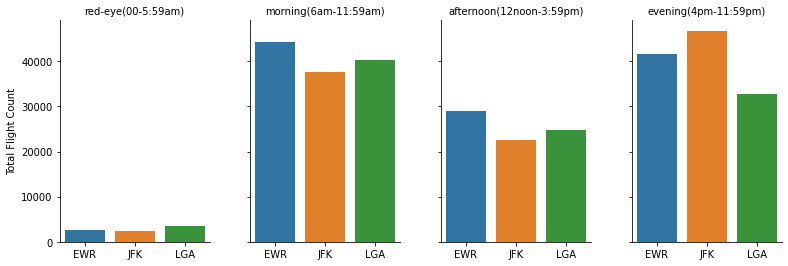

In [ ]:
fig_3 = None
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
assert fig_3.figure.get_axes()[0].get_title() == 'red-eye(00-5:59am)'
assert fig_3.figure.get_axes()[0].get_ylabel() == 'Flight Count'
assert fig_3.figure.get_axes()[1].get_title() == 'morning(6am-11:59am)'